<a href="https://colab.research.google.com/github/EduardEND/Lovelace-Team-Group-1/blob/main/EDA_Lab_1n2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import pandas as pd


In [2]:
import io
import urllib.request
import pandas as pd

url = "https://raw.githubusercontent.com/EduardEND/Lovelace-Team-Group-1/refs/heads/main/cleaned_heart_data.csv"
with urllib.request.urlopen(url) as f:
    lines = f.read().decode("utf-8").splitlines()

# Strip the extra enclosing quotes and whitespace from each line
cleaned_lines = [line.strip().strip('"') for line in lines if line.strip()]

# Join the cleaned lines back and read into a DataFrame
csv_data = '\n'.join(cleaned_lines)
df = pd.read_csv(io.StringIO(csv_data))

# Remove duplicate rows immediately as part of cleaning
df = df.drop_duplicates()

In [3]:
print("Shape:", df.shape)
df.info()
df = df.rename(columns={
    "cp": "chest_pain_type",
    "trestbps": "resting_blood_pressure",
    "chol": "cholesterol",
    "fbs": "fasting_blood_sugar",
    "restecg": "resting_ecg",
    "thalach": "max_heart_rate",
    "exang": "exercise_angina",
    "oldpeak": "st_depression",
    "slope": "st_slope",
    "ca": "num_major_vessels",
    "thal": "thalassemia",
})
display(df.head())

Shape: (302, 14)
<class 'pandas.core.frame.DataFrame'>
Index: 302 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       302 non-null    int64  
 1   sex       302 non-null    int64  
 2   cp        302 non-null    int64  
 3   trestbps  302 non-null    int64  
 4   chol      302 non-null    int64  
 5   fbs       302 non-null    int64  
 6   restecg   302 non-null    int64  
 7   thalach   302 non-null    int64  
 8   exang     302 non-null    int64  
 9   oldpeak   302 non-null    float64
 10  slope     302 non-null    int64  
 11  ca        302 non-null    int64  
 12  thal      302 non-null    int64  
 13  target    302 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 35.4 KB


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


In [4]:
df.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
age,302.0,54.42,9.05,29.0,48.00,55.5,61.00,77.0
sex,302.0,0.68,0.47,0.0,0.00,1.0,1.00,1.0
chest_pain_type,302.0,0.96,1.03,0.0,0.00,1.0,2.00,3.0
resting_blood_pressure,302.0,131.60,17.56,94.0,120.00,130.0,140.00,200.0
cholesterol,302.0,246.50,51.75,126.0,211.00,240.5,274.75,564.0
fasting_blood_sugar,302.0,0.15,0.36,0.0,0.00,0.0,0.00,1.0
resting_ecg,302.0,0.53,0.53,0.0,0.00,1.0,1.00,2.0
max_heart_rate,302.0,149.57,22.90,71.0,133.25,152.5,166.00,202.0
exercise_angina,302.0,0.33,0.47,0.0,0.00,0.0,1.00,1.0
st_depression,302.0,1.04,1.16,0.0,0.00,0.8,1.60,6.2


In [5]:
# Verify cleaning results
print("Missing values per column:")
print(df.isna().sum())
print("\nRemaining duplicate rows:", df.duplicated().sum())

Missing values per column:
age                       0
sex                       0
chest_pain_type           0
resting_blood_pressure    0
cholesterol               0
fasting_blood_sugar       0
resting_ecg               0
max_heart_rate            0
exercise_angina           0
st_depression             0
st_slope                  0
num_major_vessels         0
thalassemia               0
target                    0
dtype: int64

Remaining duplicate rows: 0


In [6]:
df.to_csv('/content/cleaned_heart_data.csv', index=False)
print("Data successfully saved to /content/cleaned_heart_data.csv")

Data successfully saved to /content/cleaned_heart_data.csv


/tmp/ipykernel_4162/1152007066.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `histplot` (an axes-level function for histograms).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['resting_blood_pressure'], bins=10)


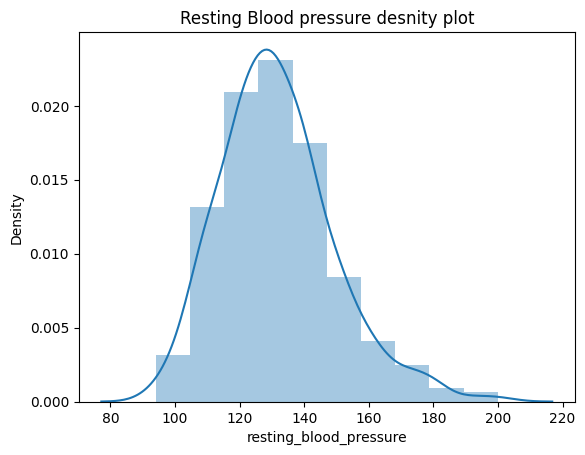

In [11]:
sns.distplot(df['resting_blood_pressure'], bins=10)
plt.title('Resting Blood pressure desnity plot');

Text(0.5, 1.0, 'Count of target feature by sex')

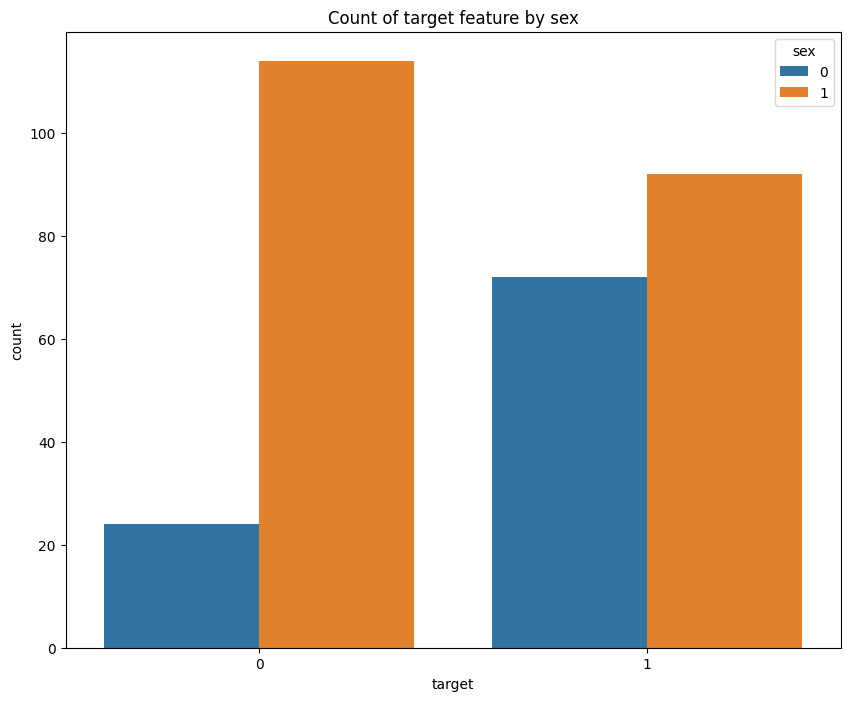

In [12]:
plt.rcParams['figure.figsize'] = (10,8)
sns.countplot(x='target', hue='sex', data=df);
plt.title('Count of target feature by sex')

Text(0.5, 1.0, ' Cholesterol vs Blood pressure in rest')

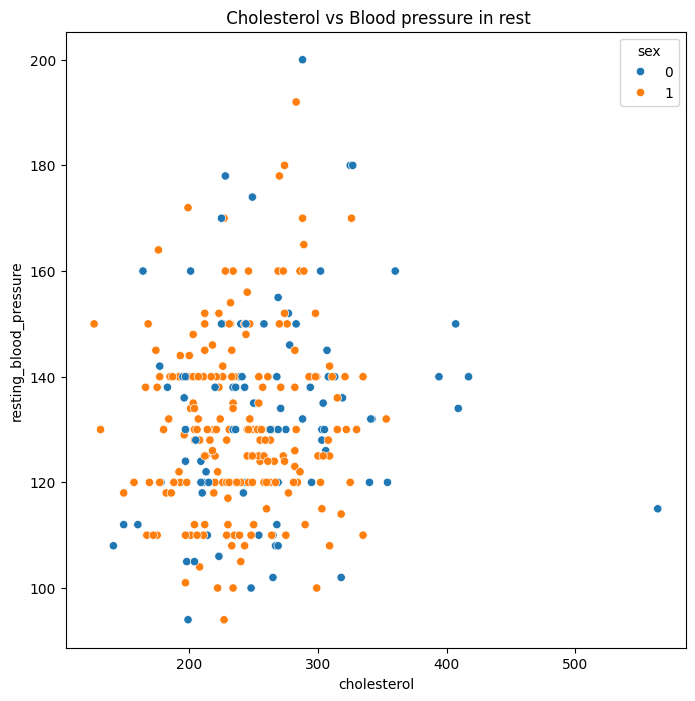

In [13]:
plt.rcParams['figure.figsize'] = (8,8)
sns.scatterplot(x='cholesterol', y='resting_blood_pressure', hue='sex', size=None, data=df)
plt.title(' Cholesterol vs Blood pressure in rest')

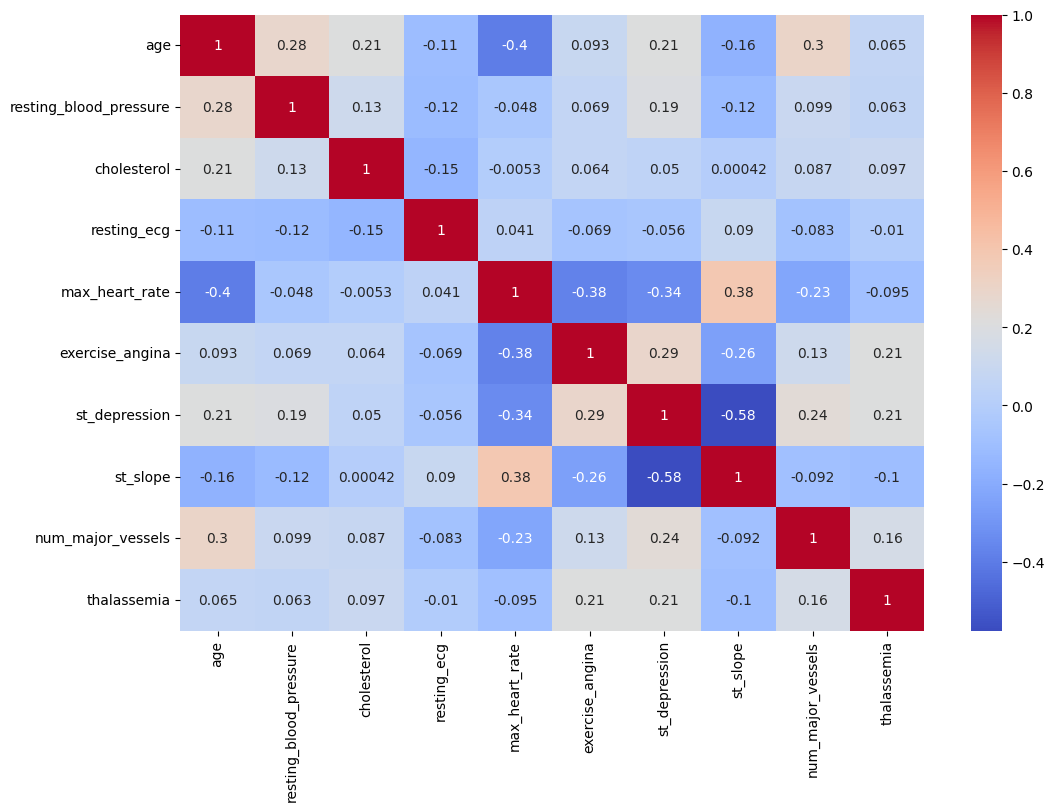

In [10]:
plt.figure(figsize=(12,8))
sns.heatmap(df.drop(['target', 'sex', 'chest_pain_type', 'fasting_blood_sugar'], axis=1).corr(), annot=True, cmap='coolwarm');

In [7]:
# Remove the duplicate row to complete the data cleaning as requested
df_clean = df.drop_duplicates()
print(f"Original shape: {df.shape}")
print(f"Cleaned shape (after removing duplicates): {df_clean.shape}")

# Save the final cleaned data to the destination
df_clean.to_csv('/content/cleaned_heart_data.csv', index=False)
print("Fully cleaned data successfully saved to /content/cleaned_heart_data.csv")

Original shape: (302, 14)
Cleaned shape (after removing duplicates): (302, 14)
Fully cleaned data successfully saved to /content/cleaned_heart_data.csv


In [8]:
# Check if any duplicate rows remain in the cleaned DataFrame
remaining_duplicates = df_clean.duplicated().sum()
print(f"Remaining duplicate rows in df_clean: {remaining_duplicates}")
display(df_clean.head())

Remaining duplicate rows in df_clean: 0


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
